In [49]:
# Data handling
import pandas as pd
import numpy as np
import tensorflow as tf

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

#print("Libraries imported successfully!")

In [2]:
df = pd.read_excel("Summary of Analyses.xls")

In [3]:
print("Shape:", df.shape)

Shape: (9076, 54)


In [4]:
drop_cols = [
    'LINK_DRV',
    'LINK_SAM',
    'LINK_REF',
    'DLAB_CODE',
    'SAMPLE_ID',
    'STCNTCODE',
    'STCTNAME',
    'CNTYNAME',
    'FIELD_CODE',
    'FIELD_NAME',
    'AAPG_NO',
    'GEO_AGE',
    'FORM_CODE',
    'FORM_NAME',
    'FORM_CDMOD',
    'FORM_NMOD',
    'LITH_CODE',
    'REGION_NO',
    'CNTYCODE',
    'S_YEAR'
]

df = df.drop(columns=drop_cols)

print(df.shape)
print(df.columns.tolist())

(9076, 34)
['DEPTH_TOP', 'DEPTH_BOT', 'SGRAV_CRUD', 'API_CRUDE', 'POUR_PTSGN', 'POUR_POINT', 'CRN', 'CRN_SIGN', 'SUA77', 'SU77', 'SUA100', 'SU100', 'COLOUR', 'NRES_SIGN', 'NRES', 'SRES_SIGN', 'SRES', 'SRC_SIGN', 'SRC', 'CAR_RES_WT', 'CAR_CR_WT', 'LT_GAS_VOL', 'DLG', 'GAS_NP_VOL', 'DGN', 'KER_DISVOL', 'DKD', 'GASOIL_VOL', 'AVED', 'NON_LUBVOL', 'MED_LUBVOL', 'VIS_LUBVOL', 'RESDUM_VOL', 'SGRR']


In [5]:
print(df.head())
print(df.info())
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nSummary Statistics:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

   DEPTH_TOP  DEPTH_BOT  SGRAV_CRUD  API_CRUDE POUR_PTSGN  POUR_POINT  CRN  \
0      450.0        0.0       0.796       46.3         -1         0.0  0.0   
1      708.0        0.0       0.822       40.6         -1         0.0  0.0   
2        0.0        0.0       0.850       35.0         -1         0.0  0.0   
3        0.0        0.0       0.828       39.4         -1         0.0  0.0   
4        0.0        0.0       0.874       30.4          <         5.0  0.0   

   CRN_SIGN SUA77  SU77 SUA100  SU100 COLOUR  NRES_SIGN  NRES  SRES_SIGN  \
0       NaN   NaN   0.0    NaN    0.0     -1        NaN   0.0        NaN   
1       NaN   NaN   0.0    NaN    0.0     -1        NaN   0.0        NaN   
2       NaN   NaN   0.0    NaN    0.0     -1        NaN   0.0        NaN   
3       NaN   NaN   0.0    NaN    0.0     -1        NaN   0.0        NaN   
4       NaN   NaN   0.0    NaN   72.0     -1        NaN   0.0        NaN   

   SRES SRC_SIGN   SRC  CAR_RES_WT  CAR_CR_WT  LT_GAS_VOL    DLG  GAS_NP_V

,DEPTH_TOP,DEPTH_BOT,SGRAV_CRUD,API_CRUDE,POUR_POINT,CRN,CRN_SIGN,SU77,SU100,NRES_SIGN,NRES,SRES_SIGN,SRES,SRC,CAR_RES_WT,CAR_CR_WT,LT_GAS_VOL,DLG,GAS_NP_VOL,DGN,KER_DISVOL,DKD,GASOIL_VOL,AVED,NON_LUBVOL,MED_LUBVOL,VIS_LUBVOL,RESDUM_VOL,SGRR
count,9073.000000,9073.000000,9074.000000,9074.000000,9073.000000,9074.000000,91.0,9071.000000,9073.000000,0.0,9074.000000,0.0,9074.000000,9074.000000,9076.000000,9076.000000,9076.000000,9064.000000,9076.000000,9064.000000,9076.000000,9064.000000,9076.000000,9064.000000,9076.000000,9076.000000,9076.000000,9076.000000,9076.000000
mean,4228.422021,1913.710680,1.107416,35.838054,11.416180,0.049976,-1.0,17.356631,200.373636,NaN,0.013274,NaN,0.059470,0.598242,6.424945,2.064896,7.922609,0.602564,28.499956,0.724702,9.867805,0.700647,17.269293,0.829224,10.567871,5.529749,1.808374,24.750948,0.883229
std,3259.524056,3358.386258,3.524710,8.885760,17.571793,0.098697,0.0,98.905910,809.286397,NaN,0.086025,NaN,0.380133,0.888161,4.889889,2.306013,6.492490,0.211565,14.961165,0.132217,6.619737,0.277662,8.479459,0.121727,3.531750,2.571000,3.463586,12.559806,0.247646
min,0.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,-1.0,0.000000,0.000000,NaN,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.459000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1607.000000,0.000000,0.821000,31.300000,0.000000,0.000000,-1.0,0.000000,37.000000,NaN,0.000000,NaN,0.000000,0.120000,3.200000,0.500000,3.400000,0.667000,19.800000,0.735000,4.900000,0.804000,12.700000,0.841000,9.100000,4.300000,0.000000,17.400000,0.925000
50%,3794.000000,0.000000,0.841000,37.000000,5.000000,0.001000,-1.0,0.000000,43.000000,NaN,0.000000,NaN,0.000000,0.230000,5.600000,1.400000,7.500000,0.684000,29.300000,0.744000,10.000000,0.811000,15.700000,0.846000,10.400000,6.000000,0.000000,23.200000,0.945000
75%,6258.000000,3284.000000,0.871000,40.900000,10.000000,0.066000,-1.0,0.000000,58.000000,NaN,0.000000,NaN,0.000000,0.610000,8.800000,2.700000,11.000000,0.698000,35.600000,0.757000,13.600000,0.814000,19.700000,0.852000,12.000000,7.100000,2.200000,30.700000,0.970000
max,17361.000000,18131.000000,90.000000,72.400000,230.000000,0.955000,-1.0,6000.000000,21794.000000,NaN,1.514000,NaN,6.060000,13.080000,77.100000,19.300000,83.200000,0.848000,97.000000,0.825000,69.400000,0.825000,79.900000,1.195000,52.900000,33.100000,35.900000,83.700000,1.181000



Missing Values:
DEPTH_TOP        3
DEPTH_BOT        3
SGRAV_CRUD       2
API_CRUDE        2
POUR_PTSGN      66
POUR_POINT       3
CRN              2
CRN_SIGN      8985
SUA77         8888
SU77             5
SUA100        8735
SU100            3
COLOUR           0
NRES_SIGN     9076
NRES             2
SRES_SIGN     9076
SRES             2
SRC_SIGN      9031
SRC              2
CAR_RES_WT       0
CAR_CR_WT        0
LT_GAS_VOL       0
DLG             12
GAS_NP_VOL       0
DGN             12
KER_DISVOL       0
DKD             12
GASOIL_VOL       0
AVED            12
NON_LUBVOL       0
MED_LUBVOL       0
VIS_LUBVOL       0
RESDUM_VOL       0
SGRR             0
dtype: int64

Duplicate rows:
1


In [6]:
df = df.drop(columns=[
    'CRN_SIGN',
    'NRES_SIGN',
    'SRES_SIGN',
    'SRC_SIGN',
    'SUA77',
    'SUA100'
])

In [7]:
minus_one_count = (df.astype(str) == '-1').sum()
minus_one_percentage = (df.astype(str) == '-1').mean() * 100

result = pd.DataFrame({
    'Count of -1': minus_one_count,
    'Percentage of -1': minus_one_percentage
})

print(result.sort_values('Percentage of -1', ascending=False))

            Count of -1  Percentage of -1
COLOUR             5579         61.469810
POUR_PTSGN         5179         57.062583
DEPTH_TOP             0          0.000000
DEPTH_BOT             0          0.000000
API_CRUDE             0          0.000000
SGRAV_CRUD            0          0.000000
CRN                   0          0.000000
POUR_POINT            0          0.000000
SU77                  0          0.000000
SU100                 0          0.000000
NRES                  0          0.000000
SRES                  0          0.000000
SRC                   0          0.000000
CAR_RES_WT            0          0.000000
CAR_CR_WT             0          0.000000
LT_GAS_VOL            0          0.000000
DLG                   0          0.000000
GAS_NP_VOL            0          0.000000
DGN                   0          0.000000
KER_DISVOL            0          0.000000
DKD                   0          0.000000
GASOIL_VOL            0          0.000000
AVED                  0          0

In [8]:
df = df.drop(columns=[
    'COLOUR'
])

In [9]:
# One-hot encoding
df = pd.get_dummies(
    df,
    columns=['POUR_PTSGN'],
    drop_first=False,
    dtype=int
)

# Explicitly remove the -1 categories
df = df.drop(columns=[
    'POUR_PTSGN_-1'
], errors='ignore')

In [10]:
# Create qualifier flags (2nd method)

#df['POUR_POINT_LT'] = (df['POUR_PTSGN'] == '<').astype(int)

#df['SU100_LT'] = (df['SUA100'] == '<').astype(int)
#df['SU100_GT'] = (df['SUA100'] == '>').astype(int)

#df['SRC_LT'] = (df['SRC_SIGN'] == '<').astype(int)


# Drop original qualifier columns

#df = df.drop(columns=[
 #   'POUR_PTSGN',
  #  'SUA77',
   # 'SUA100',
    #'SRC_SIGN'
#])

In [11]:
print("Shape:", df.shape)

Shape: (9076, 27)


In [12]:
# Find numerical columns that have missing values
numeric_cols = df.select_dtypes(include=np.number).columns
numeric_cols = numeric_cols[df[numeric_cols].isnull().any()]

# Fill missing values with the median of each column
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

In [13]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


In [14]:
df = df.drop_duplicates()

In [15]:
constant_cols = df.columns[df.nunique() <= 1]

print("Constant columns:")
print(constant_cols.tolist())

Constant columns:
[]


In [16]:
print(df.dtypes)

DEPTH_TOP       float64
DEPTH_BOT       float64
SGRAV_CRUD      float64
API_CRUDE       float64
POUR_POINT      float64
CRN             float64
SU77            float64
SU100           float64
NRES            float64
SRES            float64
SRC             float64
CAR_RES_WT      float64
CAR_CR_WT       float64
LT_GAS_VOL      float64
DLG             float64
GAS_NP_VOL      float64
DGN             float64
KER_DISVOL      float64
DKD             float64
GASOIL_VOL      float64
AVED            float64
NON_LUBVOL      float64
MED_LUBVOL      float64
VIS_LUBVOL      float64
RESDUM_VOL      float64
SGRR            float64
POUR_PTSGN_<      int64
dtype: object


In [17]:
print(df.describe().T)

               count         mean          std    min       25%       50%  \
DEPTH_TOP     9075.0  4228.326281  3259.171200  0.000  1608.500  3794.000   
DEPTH_BOT     9075.0  1913.288926  3358.136289  0.000     0.000     0.000   
SGRAV_CRUD    9075.0     1.107386     3.524517  0.000     0.821     0.841   
API_CRUDE     9075.0    35.838182     8.885279  0.000    31.300    37.000   
POUR_POINT    9075.0    11.414766    17.570115 -1.000     0.000     5.000   
CRN           9075.0     0.049971     0.098693  0.000     0.000     0.001   
SU77          9075.0    17.348981    98.884779  0.000     0.000     0.000   
SU100         9075.0   200.338953   809.200577  0.000    37.000    43.000   
NRES          9075.0     0.013273     0.086020  0.000     0.000     0.000   
SRES          9075.0     0.059463     0.380112  0.000     0.000     0.000   
SRC           9075.0     0.598202     0.888121  0.000     0.120     0.230   
CAR_RES_WT    9075.0     6.425653     4.889693  0.000     3.200     5.600   

In [18]:
print(df['POUR_POINT'].value_counts().sort_index())
print(df['POUR_POINT'].nlargest(20))

POUR_POINT
-1.0        60
 0.0      2591
 5.0      3978
 9.0         2
 10.0      251
 12.0        1
 14.0        2
 15.0      287
 16.0        1
 20.0      321
 21.0        2
 23.0        1
 25.0      240
 26.0        2
 28.0        2
 29.0        1
 30.0      210
 32.0        2
 35.0      191
 40.0      212
 42.0        1
 45.0      164
 46.0        1
 49.0        1
 50.0      141
 55.0      112
 60.0       85
 65.0       57
 70.0       42
 75.0       30
 80.0       17
 85.0       15
 89.0        4
 90.0        6
 93.0        1
 94.0        1
 95.0       17
 100.0       9
 103.0       1
 105.0       4
 115.0       2
 120.0       1
 125.0       2
 130.0       2
 151.0       1
 230.0       1
Name: count, dtype: int64
6343    230.0
4240    151.0
7347    130.0
8311    130.0
7111    125.0
7346    125.0
7198    120.0
7369    115.0
8864    115.0
7107    105.0
7108    105.0
7110    105.0
7197    105.0
6433    103.0
6556    100.0
6566    100.0
7076    100.0
7127    100.0
7196    100.0
7199   

In [19]:
print(df['SU77'].value_counts().sort_index())
print(df['SU77'].nlargest(20))

SU77
0.0       7214
28.0         3
29.0         4
30.0         5
31.0        11
          ... 
800.0        1
1200.0       2
3988.0       1
4441.0       1
6000.0       1
Name: count, Length: 179, dtype: int64
6822    6000.0
6905    4441.0
6648    3988.0
2460    1200.0
7726    1200.0
6929     800.0
6640     603.0
5872     560.0
8770     560.0
6351     501.0
8840     501.0
6352     498.0
8841     498.0
8610     460.0
8355     430.0
9058     430.0
8555     400.0
5588     360.0
8710     360.0
7134     350.0
Name: SU77, dtype: float64


In [20]:
print(df['SU77'].describe())
print("\nZeros:", (df['SU77'] == 0).sum())
print("NaN:", df['SU77'].isna().sum())

count    9075.000000
mean       17.348981
std        98.884779
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      6000.000000
Name: SU77, dtype: float64

Zeros: 7214
NaN: 0


In [21]:
print(df['SU100'].describe())
print("\nZeros:", (df['SU100'] == 0).sum())
print("NaN:", df['SU100'].isna().sum())

count     9075.000000
mean       200.338953
std        809.200577
min          0.000000
25%         37.000000
50%         43.000000
75%         58.000000
max      21794.000000
Name: SU100, dtype: float64

Zeros: 170
NaN: 0


In [22]:
print(((df['SU77'] == 0) & (df['SU100'] > 0)).sum())

7046


In [23]:
df = df.drop(columns=[
    'SU77'
])

In [24]:
print(df.columns.tolist())

['DEPTH_TOP', 'DEPTH_BOT', 'SGRAV_CRUD', 'API_CRUDE', 'POUR_POINT', 'CRN', 'SU100', 'NRES', 'SRES', 'SRC', 'CAR_RES_WT', 'CAR_CR_WT', 'LT_GAS_VOL', 'DLG', 'GAS_NP_VOL', 'DGN', 'KER_DISVOL', 'DKD', 'GASOIL_VOL', 'AVED', 'NON_LUBVOL', 'MED_LUBVOL', 'VIS_LUBVOL', 'RESDUM_VOL', 'SGRR', 'POUR_PTSGN_<']


In [25]:
valid_su100 = df.loc[df['SU100'] != 0, 'SU100']

df.loc[df['SU100'] == 0, 'SU100'] = valid_su100.median()

In [26]:
df.shape

(9075, 26)

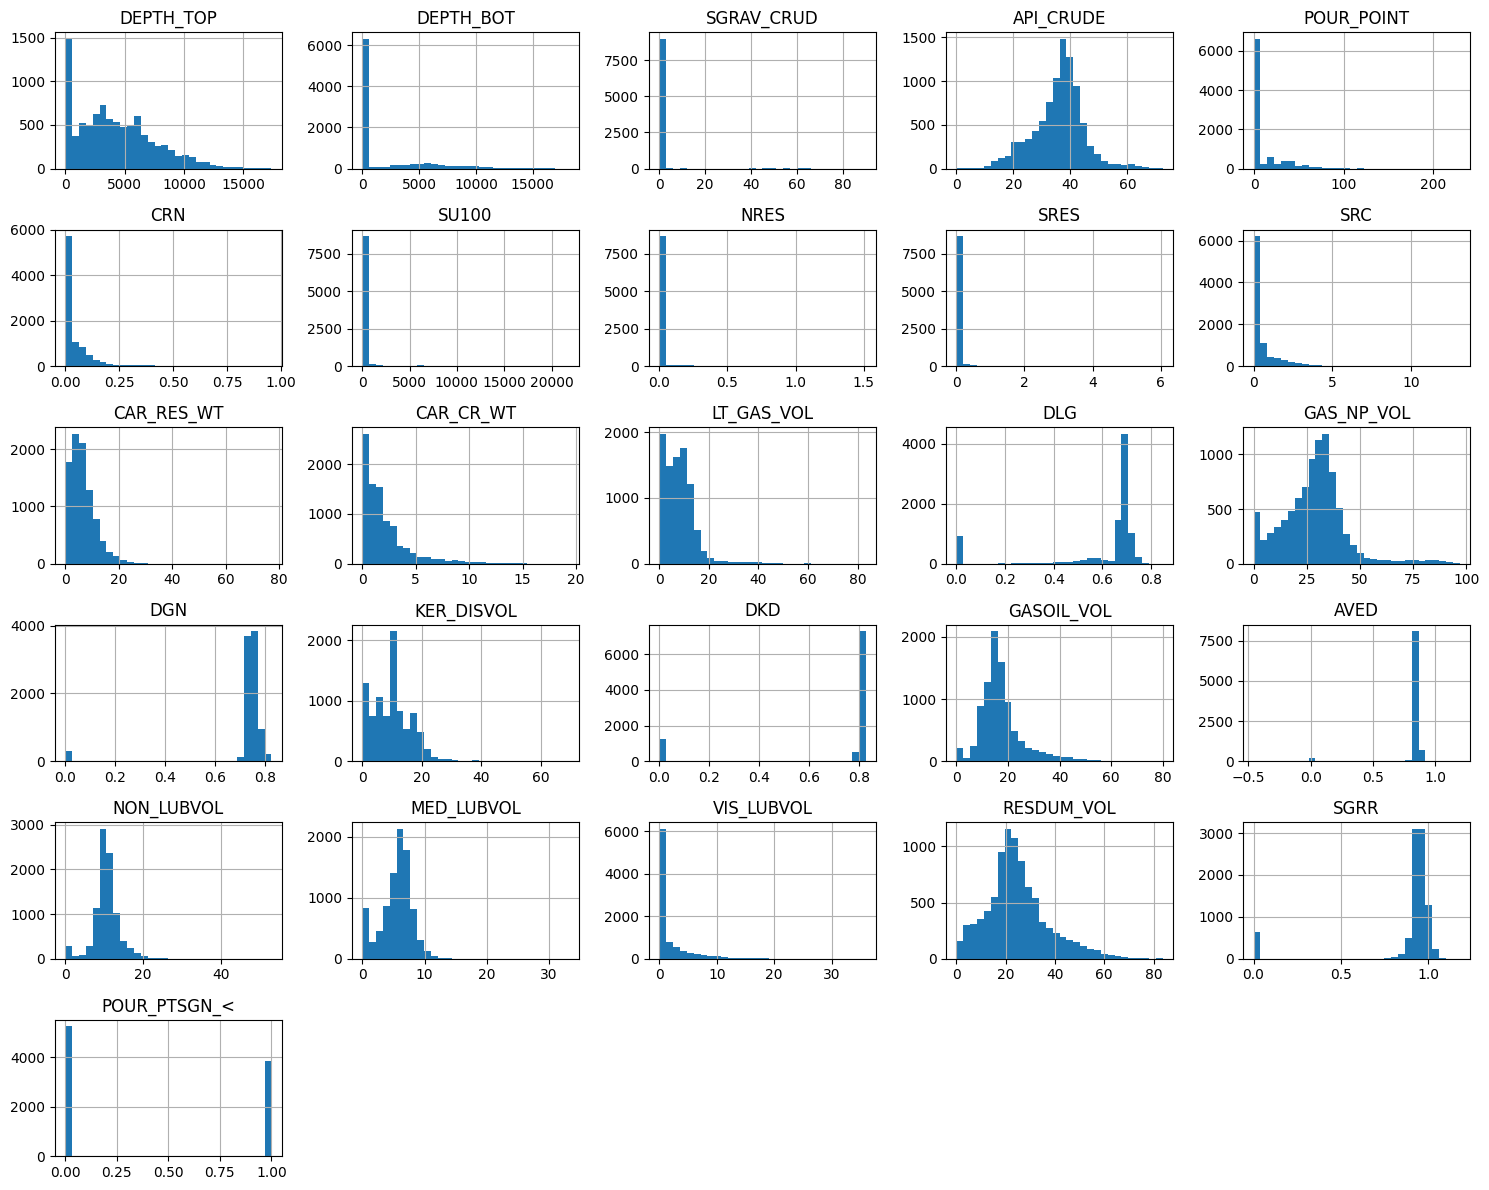

In [27]:
df.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

In [28]:
#input features
input_features = [
    'DEPTH_TOP',
    'DEPTH_BOT',
    'SGRAV_CRUD',
    'API_CRUDE',
    'POUR_POINT',
    'CRN',
    'SU100',
    'NRES',
    'SRES',
    'SRC',
    'CAR_RES_WT',
    'CAR_CR_WT',
    'DLG',
    'DGN',
    'DKD',
    'AVED',
    'SGRR',
    'POUR_PTSGN_<'
]

#output features
output_features = [
    'LT_GAS_VOL',
    'GAS_NP_VOL',
    'KER_DISVOL',
    'GASOIL_VOL',
    'NON_LUBVOL',
    'MED_LUBVOL',
    'VIS_LUBVOL',
    'RESDUM_VOL'
]

In [29]:
X = df[input_features]
y = df[output_features]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInputs:")
print(X.columns.tolist())

print("\nOutputs:")
print(y.columns.tolist())

X shape: (9075, 18)
y shape: (9075, 8)

Inputs:
['DEPTH_TOP', 'DEPTH_BOT', 'SGRAV_CRUD', 'API_CRUDE', 'POUR_POINT', 'CRN', 'SU100', 'NRES', 'SRES', 'SRC', 'CAR_RES_WT', 'CAR_CR_WT', 'DLG', 'DGN', 'DKD', 'AVED', 'SGRR', 'POUR_PTSGN_<']

Outputs:
['LT_GAS_VOL', 'GAS_NP_VOL', 'KER_DISVOL', 'GASOIL_VOL', 'NON_LUBVOL', 'MED_LUBVOL', 'VIS_LUBVOL', 'RESDUM_VOL']


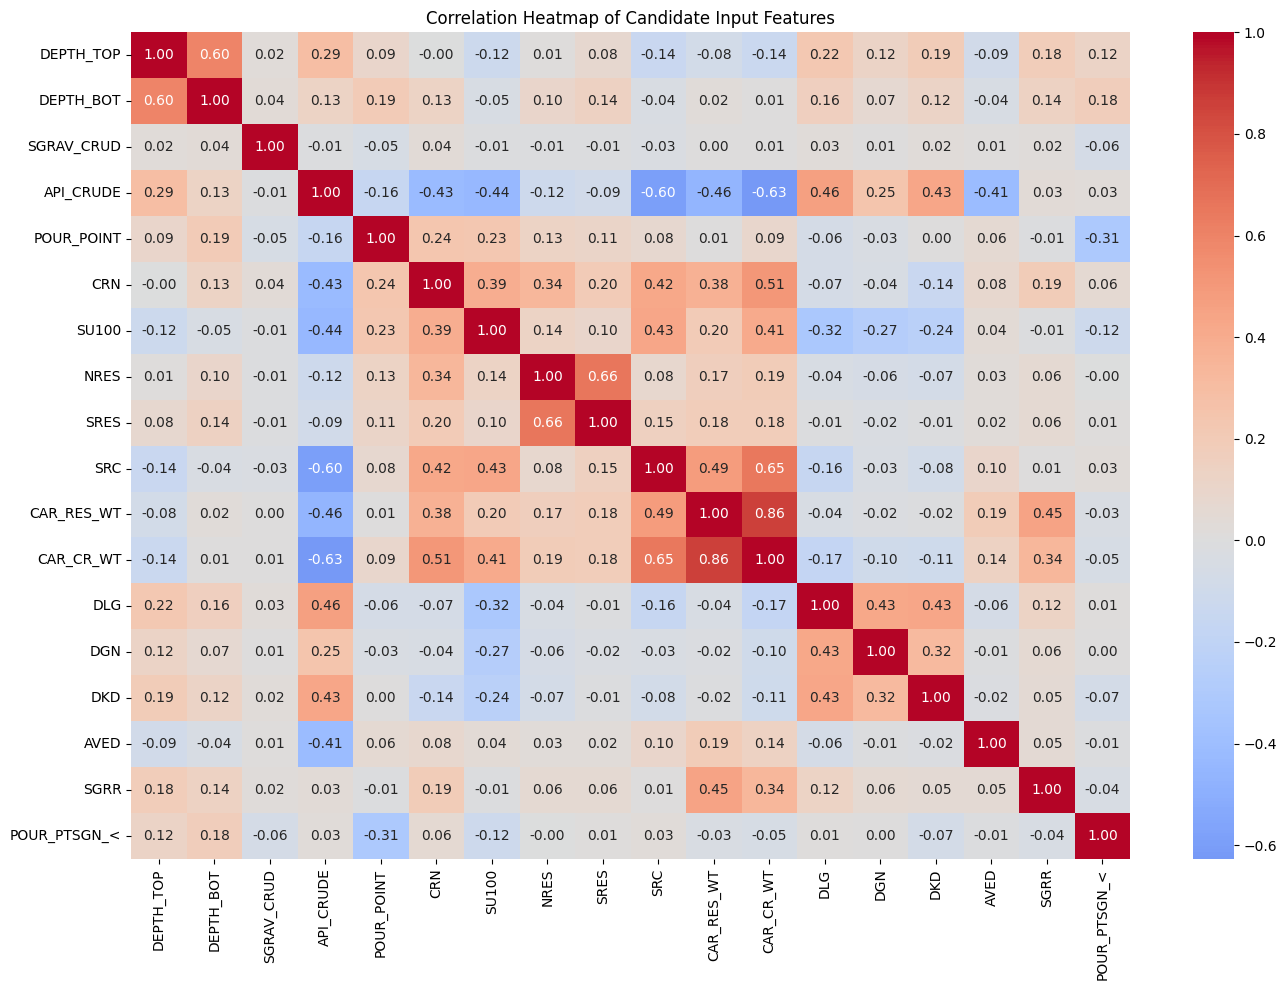

In [30]:
input_corr = X.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    input_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Candidate Input Features")
plt.tight_layout()
plt.show()

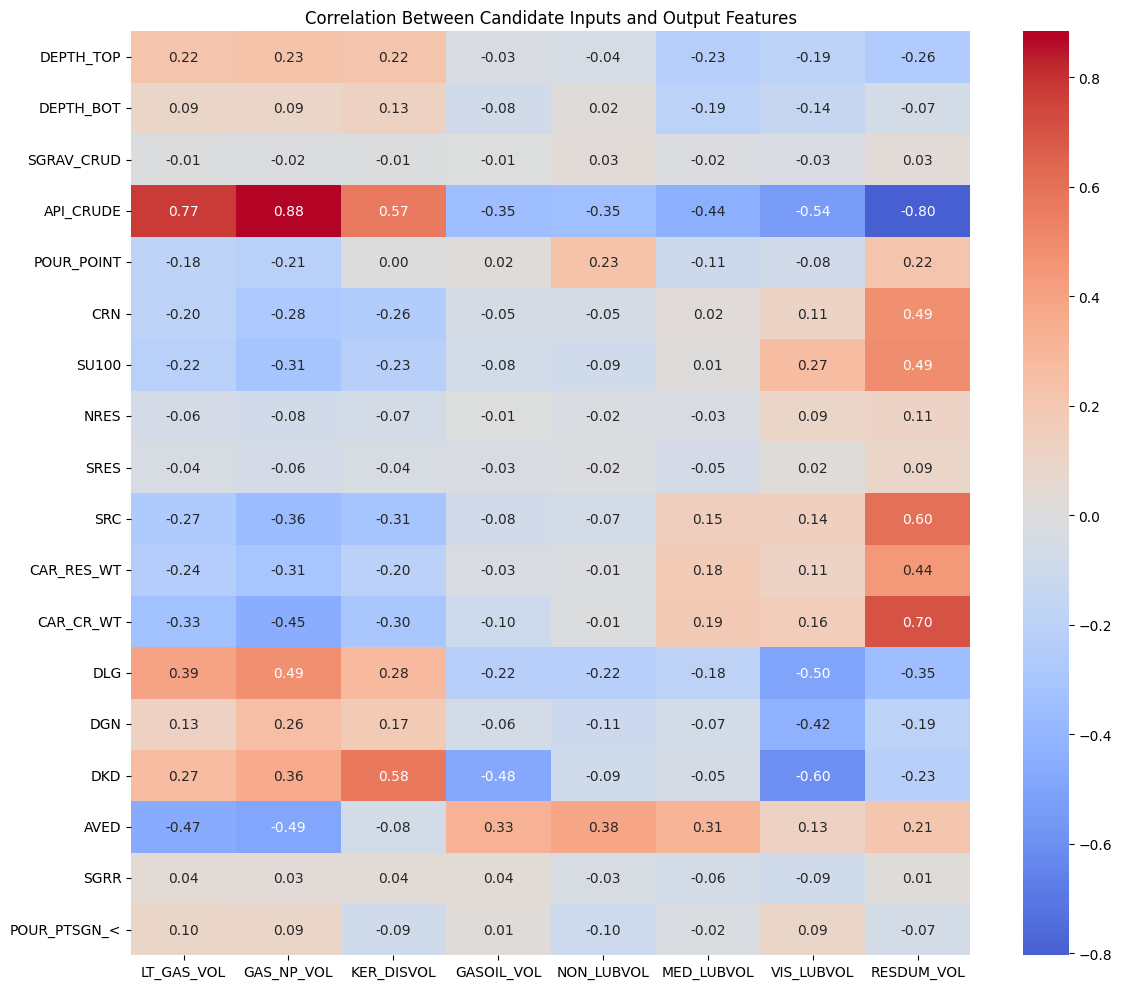

In [31]:
input_output_corr = df[input_features + output_features].corr().loc[
    input_features,
    output_features
]

plt.figure(figsize=(12, 10))
sns.heatmap(
    input_output_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Candidate Inputs and Output Features")
plt.tight_layout()
plt.show()

In [32]:
drop_cols = [
    'DEPTH_TOP',
    'DEPTH_BOT',
    'SGRAV_CRUD',
    'NRES',
    'SRES',
    'CAR_RES_WT',
    'SGRR',
    'POUR_PTSGN_<'
]

X = X.drop(columns=drop_cols)

In [33]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInputs:")
print(X.columns.tolist())

print("\nOutputs:")
print(y.columns.tolist())

X shape: (9075, 10)
y shape: (9075, 8)

Inputs:
['API_CRUDE', 'POUR_POINT', 'CRN', 'SU100', 'SRC', 'CAR_CR_WT', 'DLG', 'DGN', 'DKD', 'AVED']

Outputs:
['LT_GAS_VOL', 'GAS_NP_VOL', 'KER_DISVOL', 'GASOIL_VOL', 'NON_LUBVOL', 'MED_LUBVOL', 'VIS_LUBVOL', 'RESDUM_VOL']


In [34]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: divide the temporary 30% equally
X_cv, X_test, y_cv, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

# Delete temporary variables
del X_temp, y_temp

# Check the final shapes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_cv.shape, y_cv.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (6352, 10) (6352, 8)
Validation set: (1361, 10) (1361, 8)
Testing set: (1362, 10) (1362, 8)


In [35]:
np.random.seed(1234)
tf.random.set_seed(1234)

# Scale input features
X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_cv_scaled = X_scaler.transform(X_cv)
X_test_scaled = X_scaler.transform(X_test)


# Scale output features
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(y_train)
y_cv_scaled = y_scaler.transform(y_cv)
y_test_scaled = y_scaler.transform(y_test)

#ANN

In [36]:
# Store ANN results
ann_results = []
hidden_layer_results = []

# Variables for the best model
best_hidden_layers = None

best_neuron_configuration = None
best_learning_rate = None
best_rmse_neurons = float("inf")
best_neuron_model = None

best_rmse_ann = float("inf")
best_ann_model = None

# Hyperparameter options
hidden_layer_list = [1, 2]
neurons_list = [16, 32]
learning_rate_list = [0.001, 0.01]

epoch = 100
batch = 32

In [37]:
# Store hidden-layer tuning results
hidden_layer_results = []

best_hidden_layers = None
best_rmse_hidden_layers = float("inf")
best_hidden_layer_model = None

for hidden_layers in hidden_layer_list:

    tf.keras.backend.clear_session()
    tf.random.set_seed(1234)

    model = Sequential()

    # Input layer
    model.add(Input(shape=(X_train_scaled.shape[1],)))

    # Add hidden layers
    for i in range(hidden_layers):
        model.add(Dense(32, activation='relu'))

    # Output layer: 8 predicted values
    model.add(Dense(len(output_features), activation='linear'))

    # Compile model
    model.compile(
        loss='mean_squared_error',
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
    )

    # Train model
    model.fit(
        X_train_scaled,
        y_train_scaled,
        epochs=epoch,
        batch_size=batch,
        verbose=0
    )

    # Validation predictions
    y_cv_pred = model.predict(X_cv_scaled, verbose=0)

    # Overall validation RMSE across all 8 outputs
    val_rmse = np.sqrt(
        mean_squared_error(y_cv_scaled, y_cv_pred)
    )

    # Store results
    hidden_layer_results.append({
        "Hidden Layers": hidden_layers,
        "Neurons per Layer": 32,
        "Learning Rate": 0.001,
        "Validation RMSE": val_rmse
    })

    # Save the best configuration
    if val_rmse < best_rmse_hidden_layers:
        best_rmse_hidden_layers = val_rmse
        best_hidden_layers = hidden_layers
        best_hidden_layer_model = model

# Display results
hidden_layer_results = pd.DataFrame(hidden_layer_results)

print(hidden_layer_results)
print("\nBest number of hidden layers:", best_hidden_layers)
print("Best validation RMSE:", best_rmse_hidden_layers)

   Hidden Layers  Neurons per Layer  Learning Rate  Validation RMSE
0              1                 32          0.001         0.551316
1              2                 32          0.001         0.521517

Best number of hidden layers: 2
Best validation RMSE: 0.5215171997212152


In [38]:
# Tune neuron configurations and learning rates
for learning_rate in learning_rate_list:

    if best_hidden_layers == 1:

        # One hidden layer
        for neurons in neurons_list:

            tf.keras.backend.clear_session()
            tf.random.set_seed(1234)

            model = Sequential([
                Input(shape=(X_train_scaled.shape[1],)),
                Dense(neurons, activation='relu'),
                Dense(len(output_features), activation='linear')
            ])

            model.compile(
                loss=tf.keras.losses.MeanSquaredError(),
                optimizer=tf.keras.optimizers.Adam(
                    learning_rate=learning_rate
                )
            )

            model.fit(
                X_train_scaled,
                y_train_scaled,
                epochs=epoch,
                batch_size=batch,
                verbose=0
            )

            # Validation prediction
            y_cv_pred = model.predict(
                X_cv_scaled,
                verbose=0
            )

            # Validation RMSE
            val_rmse = np.sqrt(
                mean_squared_error(
                    y_cv_scaled,
                    y_cv_pred
                )
            )

            ann_results.append({
                "Hidden Layers": 1,
                "Neuron Configuration": (neurons,),
                "Learning Rate": learning_rate,
                "Validation RMSE": val_rmse
            })

            if val_rmse < best_rmse_neurons:
                best_rmse_neurons = val_rmse
                best_neuron_configuration = (neurons,)
                best_learning_rate = learning_rate
                best_neuron_model = model

    elif best_hidden_layers == 2:

        # Two hidden layers
        for neurons_layer1 in neurons_list:
            for neurons_layer2 in neurons_list:

                tf.keras.backend.clear_session()
                tf.random.set_seed(1234)

                model = Sequential([
                    Input(shape=(X_train_scaled.shape[1],)),
                    Dense(neurons_layer1, activation='relu'),
                    Dense(neurons_layer2, activation='relu'),
                    Dense(len(output_features), activation='linear')
                ])

                model.compile(
                    loss=tf.keras.losses.MeanSquaredError(),
                    optimizer=tf.keras.optimizers.Adam(
                        learning_rate=learning_rate
                    )
                )

                model.fit(
                    X_train_scaled,
                    y_train_scaled,
                    epochs=epoch,
                    batch_size=batch,
                    verbose=0
                )

                y_cv_pred = model.predict(
                    X_cv_scaled,
                    verbose=0
                )

                val_rmse = np.sqrt(
                    mean_squared_error(
                        y_cv_scaled,
                        y_cv_pred
                    )
                )

                ann_results.append({
                    "Hidden Layers": 2,
                    "Neuron Configuration": (
                        neurons_layer1,
                        neurons_layer2
                    ),
                    "Learning Rate": learning_rate,
                    "Validation RMSE": val_rmse
                })

                if val_rmse < best_rmse_neurons:
                    best_rmse_neurons = val_rmse
                    best_neuron_configuration = (
                        neurons_layer1,
                        neurons_layer2
                    )
                    best_learning_rate = learning_rate
                    best_neuron_model = model

    elif best_hidden_layers == 3:

        # Three hidden layers
        for neurons_layer1 in neurons_list:
            for neurons_layer2 in neurons_list:
                for neurons_layer3 in neurons_list:

                    tf.keras.backend.clear_session()
                    tf.random.set_seed(1234)

                    model = Sequential([
                        Input(shape=(X_train_scaled.shape[1],)),
                        Dense(neurons_layer1, activation='relu'),
                        Dense(neurons_layer2, activation='relu'),
                        Dense(neurons_layer3, activation='relu'),
                        Dense(len(output_features), activation='linear')
                    ])

                    model.compile(
                        loss=tf.keras.losses.MeanSquaredError(),
                        optimizer=tf.keras.optimizers.Adam(
                            learning_rate=learning_rate
                        )
                    )

                    model.fit(
                        X_train_scaled,
                        y_train_scaled,
                        epochs=epoch,
                        batch_size=batch,
                        verbose=0
                    )

                    y_cv_pred = model.predict(
                        X_cv_scaled,
                        verbose=0
                    )

                    val_rmse = np.sqrt(
                        mean_squared_error(
                            y_cv_scaled,
                            y_cv_pred
                        )
                    )

                    ann_results.append({
                        "Hidden Layers": 3,
                        "Neuron Configuration": (
                            neurons_layer1,
                            neurons_layer2,
                            neurons_layer3
                        ),
                        "Learning Rate": learning_rate,
                        "Validation RMSE": val_rmse
                    })

                    if val_rmse < best_rmse_neurons:
                        best_rmse_neurons = val_rmse
                        best_neuron_configuration = (
                            neurons_layer1,
                            neurons_layer2,
                            neurons_layer3
                        )
                        best_learning_rate = learning_rate
                        best_neuron_model = model

# Display all results, sorted by validation RMSE
ann_results = pd.DataFrame(ann_results)

print(ann_results.sort_values("Validation RMSE"))

print("\nBest Hidden Layers:", best_hidden_layers)
print("Best Neuron Configuration:", best_neuron_configuration)
print("Best Learning Rate:", best_learning_rate)
print("Best Validation RMSE:", best_rmse_neurons)

   Hidden Layers Neuron Configuration  Learning Rate  Validation RMSE
7              2             (32, 32)          0.010         0.526499
6              2             (32, 16)          0.010         0.530288
3              2             (32, 32)          0.001         0.530989
1              2             (16, 32)          0.001         0.534665
2              2             (32, 16)          0.001         0.537785
5              2             (16, 32)          0.010         0.542912
4              2             (16, 16)          0.010         0.544614
0              2             (16, 16)          0.001         0.547066

Best Hidden Layers: 2
Best Neuron Configuration: (32, 32)
Best Learning Rate: 0.01
Best Validation RMSE: 0.5264989273778965


In [39]:
# Predict the scaled outputs
y_test_pred_scaled = best_neuron_model.predict(
    X_test_scaled,
    verbose=0
)

# Convert predictions back to their original scale
y_test_pred_ann = y_scaler.inverse_transform(
    y_test_pred_scaled
)

# Convert actual test outputs back to their original scale
y_test_actual = y_scaler.inverse_transform(
    y_test_scaled
)

print("Actual output shape:", y_test_actual.shape)
print("Predicted output shape:", y_test_pred_ann.shape)

Actual output shape: (1362, 8)
Predicted output shape: (1362, 8)


In [40]:
# Calculate overall test metrics
test_rmse_ann = np.sqrt(mean_squared_error(y_test_actual, y_test_pred_ann))
test_mae_ann = mean_absolute_error(y_test_actual, y_test_pred_ann)
test_r2_ann = r2_score(
    y_test_actual,
    y_test_pred_ann,
    multioutput='uniform_average'
)

print("ANN Test Performance")
print("--------------------")
print(f"Test RMSE: {test_rmse_ann:.4f}")
print(f"Test MAE:  {test_mae_ann:.4f}")
print(f"Test R²:   {test_r2_ann:.4f}")

ANN Test Performance
--------------------
Test RMSE: 3.7630
Test MAE:  2.2835
Test R²:   0.6776


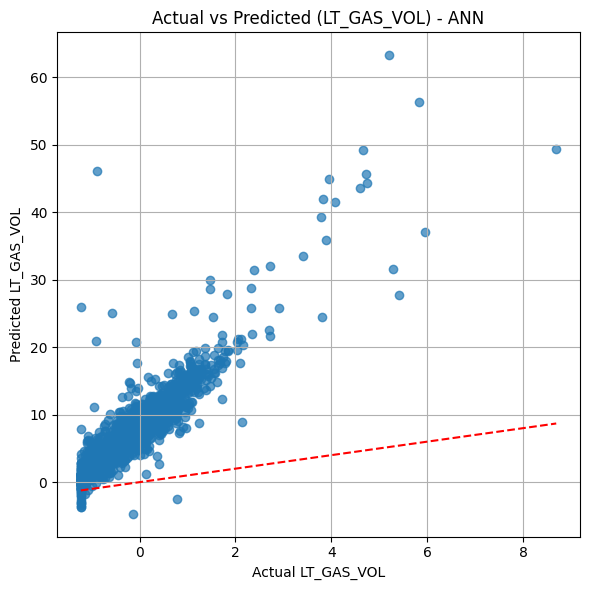

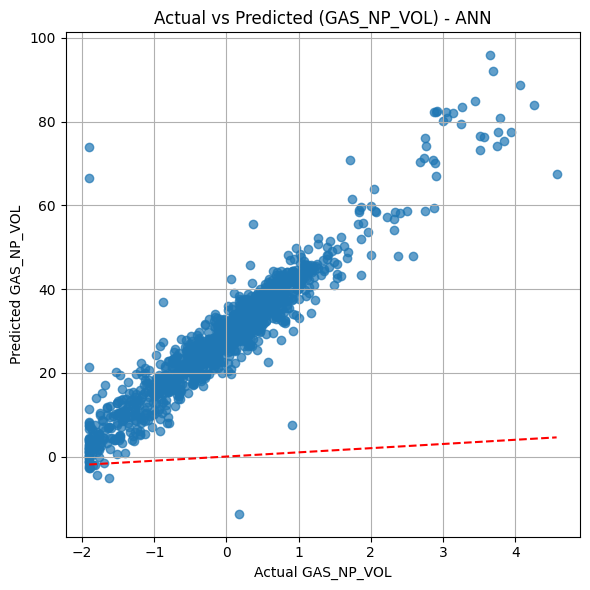

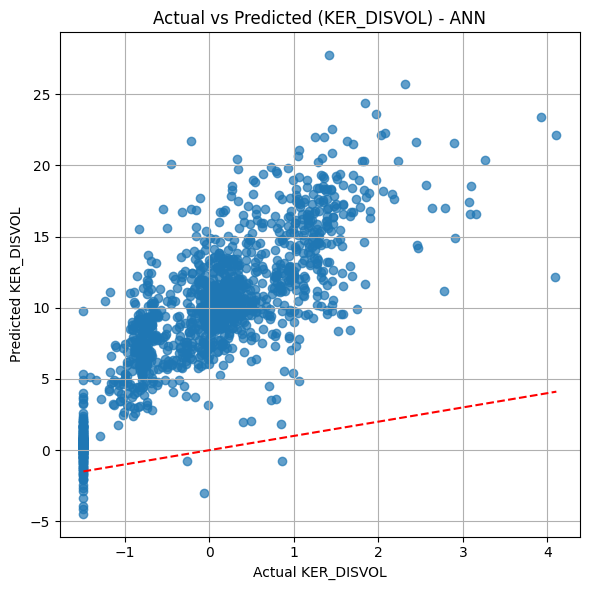

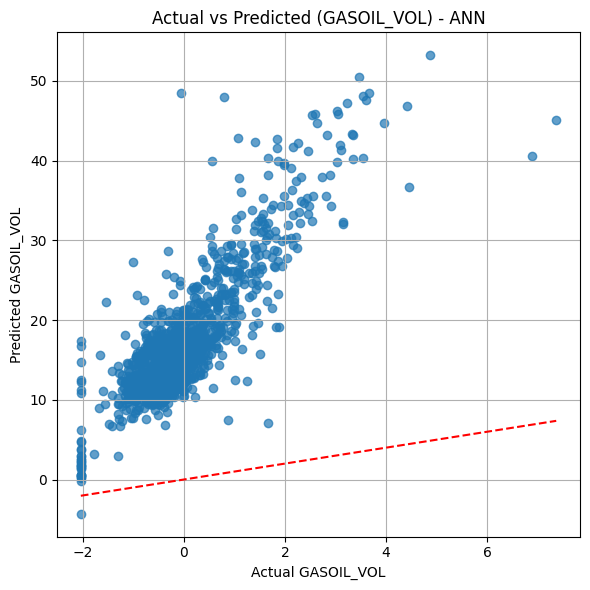

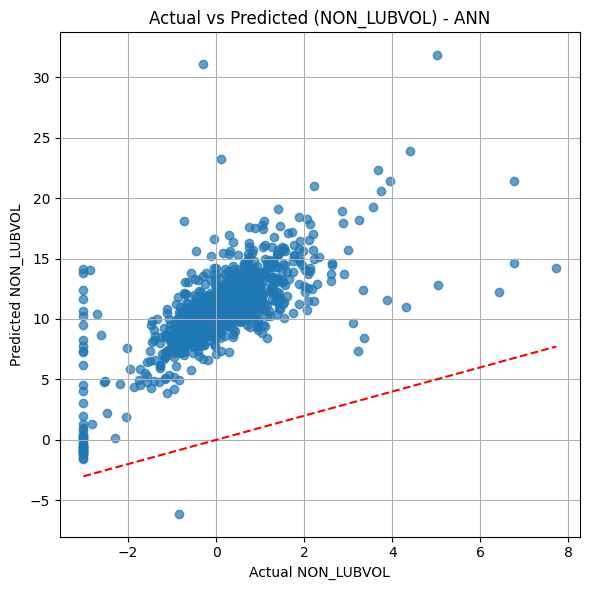

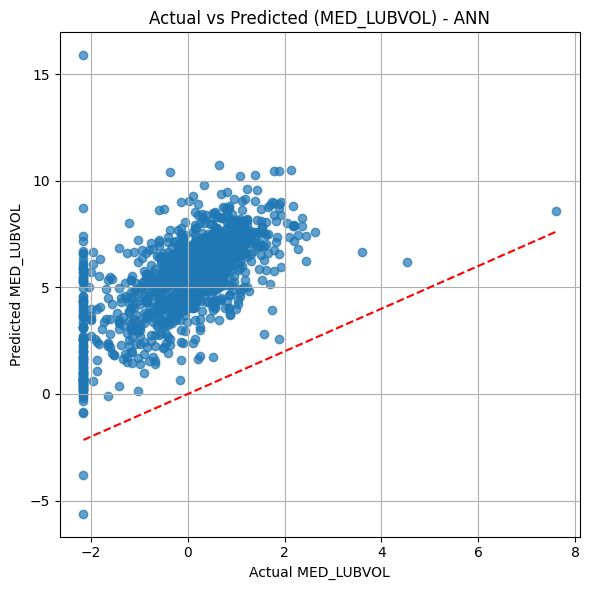

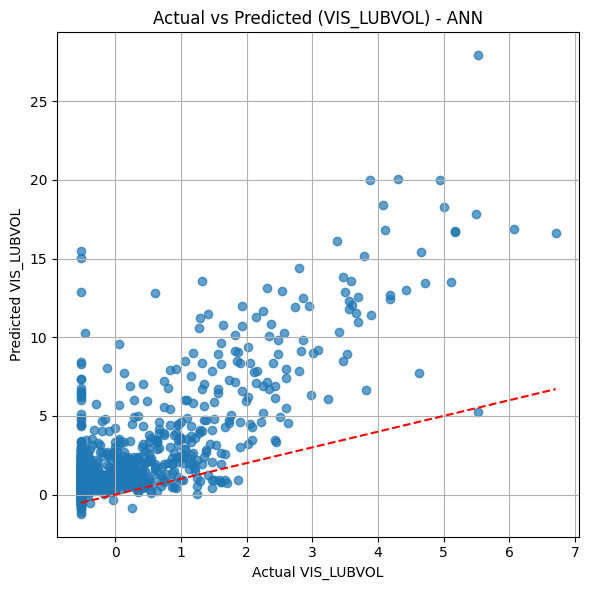

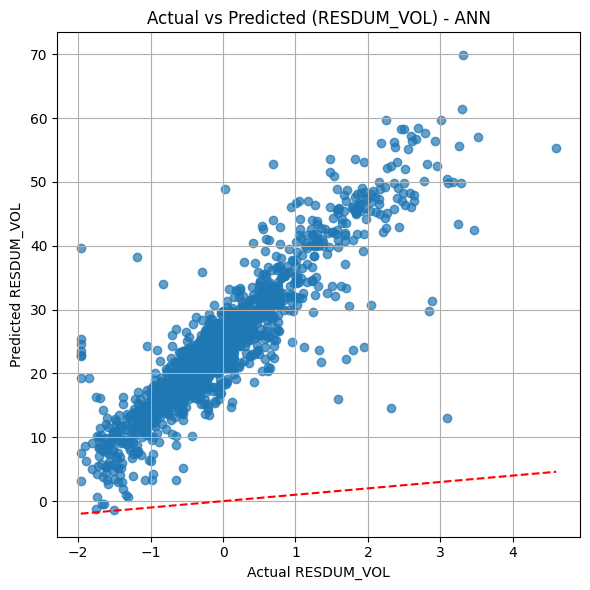

In [55]:
# Plot actual vs predicted values for ANN

for i, output in enumerate(output_features):

    plt.figure(figsize=(6, 6))

    plt.scatter(
        y_test_scaled[:, i],
        y_test_pred_ann[:, i],
        alpha=0.7
    )

    plt.plot(
        [y_test_scaled[:, i].min(), y_test_scaled[:, i].max()],
        [y_test_scaled[:, i].min(), y_test_scaled[:, i].max()],
        color="red",
        linestyle="--"
    )

    plt.xlabel("Actual " + output)
    plt.ylabel("Predicted " + output)
    plt.title("Actual vs Predicted (" + output + ") - ANN")

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [41]:
results = []

results.append({
    "Model": (
        f"ANN "
        f"(Hidden Layers {best_hidden_layers}, "
        f"Neurons {best_neuron_configuration}, "
        f"Learning Rate {best_learning_rate})"
    ),
    "Test RMSE": test_rmse_ann,
    "Test R²": test_r2_ann
})

#Linear Regression

In [42]:
# Initialize and train the model
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train_scaled)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [43]:
# Predictions on all three datasets
y_train_pred_lr = linear_model.predict(X_train_scaled)
y_cv_pred_lr = linear_model.predict(X_cv_scaled)
y_test_pred_lr = linear_model.predict(X_test_scaled)

In [44]:
# Test RMSE
test_rmse_lr = np.sqrt(
    mean_squared_error(y_test_scaled, y_test_pred_lr)
)

# Test R²
test_r2_lr = r2_score(
    y_test_scaled,
    y_test_pred_lr,
    multioutput='uniform_average'
)

print("Linear Regression Test Performance")
print("-----------------------------------")
print(f"Test RMSE: {test_rmse_lr:.4f}")
print(f"Test R²:   {test_r2_lr:.4f}")

Linear Regression Test Performance
-----------------------------------
Test RMSE: 0.6792
Test R²:   0.5433


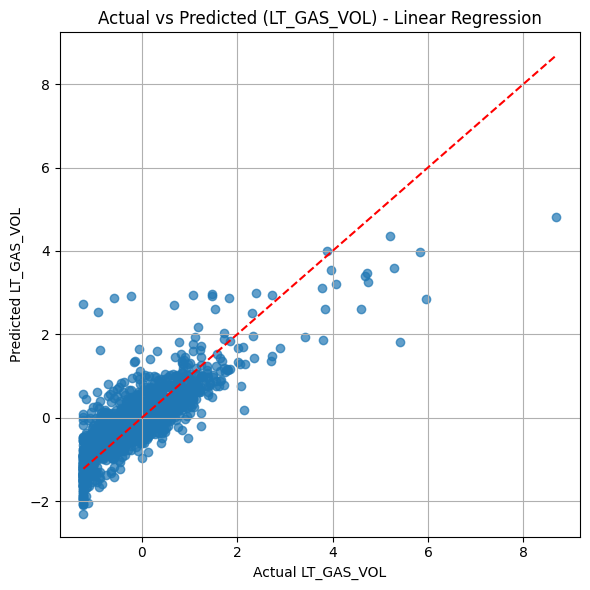

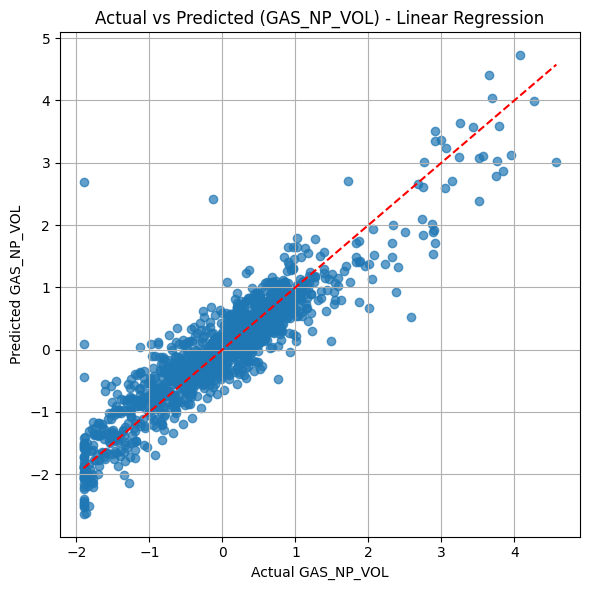

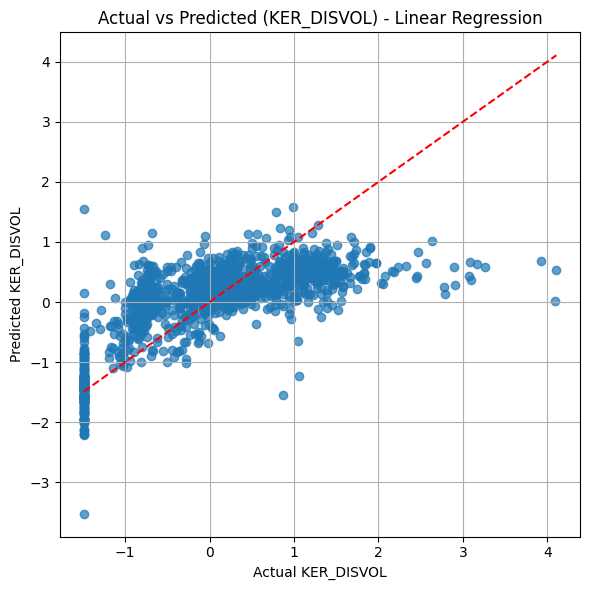

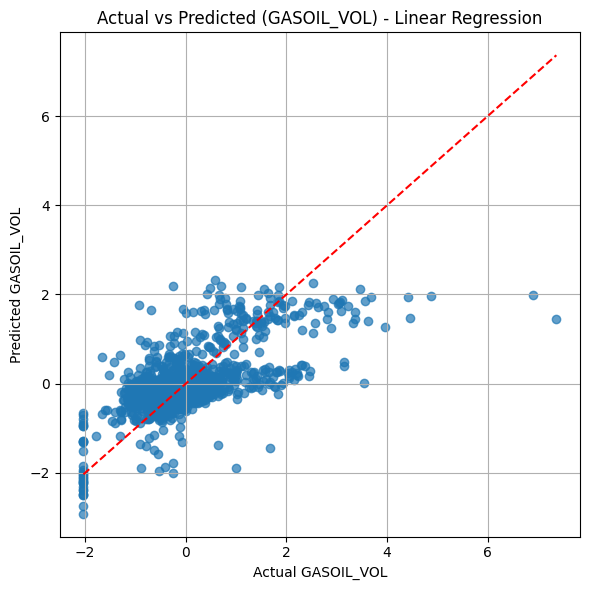

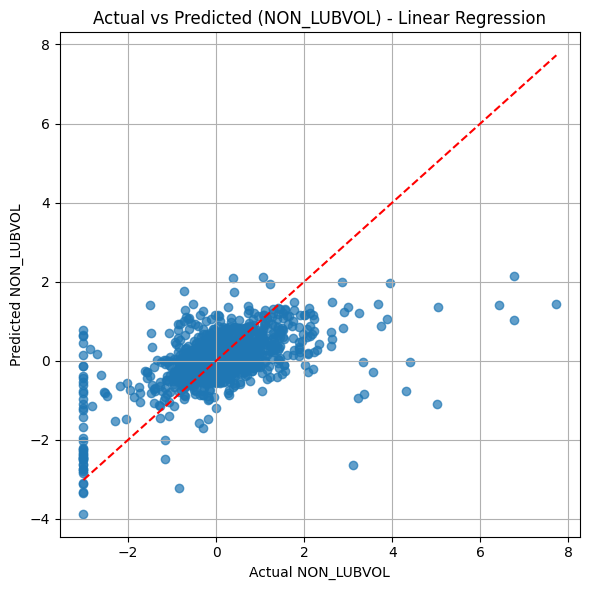

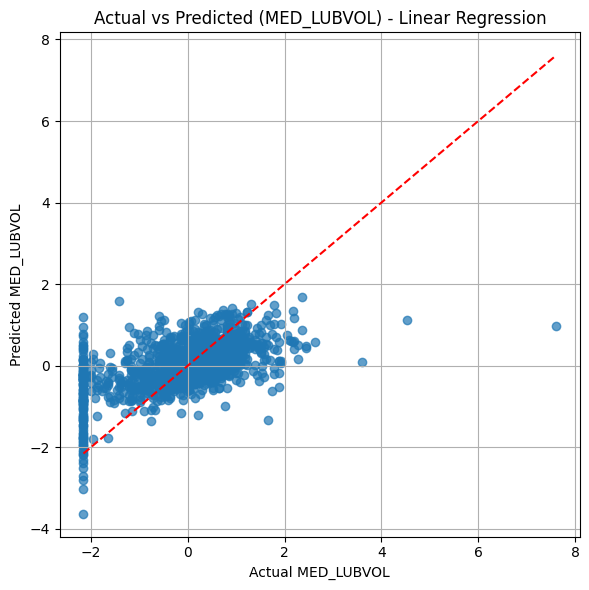

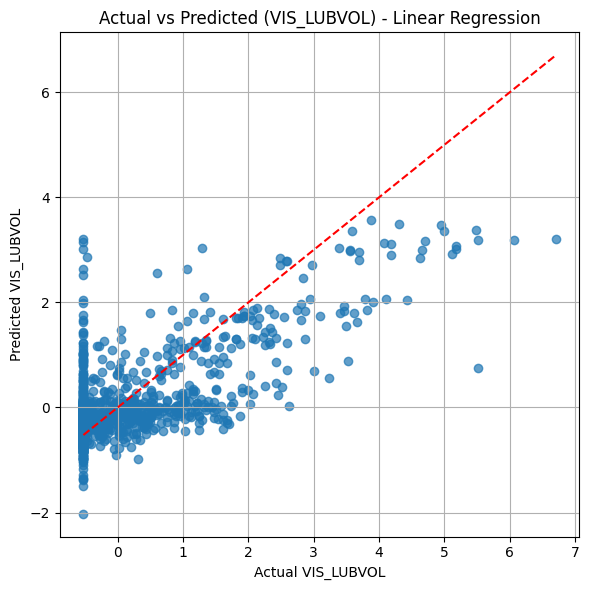

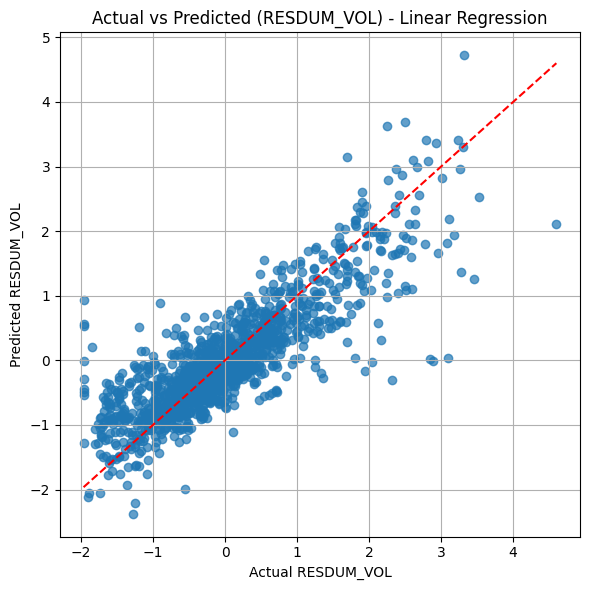

In [57]:
# Plot actual vs predicted values for Linear Regression

for i, output in enumerate(output_features):

    plt.figure(figsize=(6, 6))

    plt.scatter(
        y_test_scaled[:, i],
        y_test_pred_lr[:, i],
        alpha=0.7
    )

    plt.plot(
        [y_test_scaled[:, i].min(), y_test_scaled[:, i].max()],
        [y_test_scaled[:, i].min(), y_test_scaled[:, i].max()],
        color="red",
        linestyle="--"
    )

    plt.xlabel("Actual " + output)
    plt.ylabel("Predicted " + output)
    plt.title("Actual vs Predicted (" + output + ") - Linear Regression")

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [45]:
results.append({
    "Model": "Multiple Linear Regression (Scaled)",
    "Test RMSE": test_rmse_lr,
    "Test R²": test_r2_lr
})

#Random Forest

In [46]:
# RANDOM FOREST REGRESSION

# Variables to store the best model
best_estimators_forest = None
best_depth_forest = None
best_min_samples_forest = None

best_rmse_forest = float("inf")

best_random_forest_model = None

print("Random Forest setup completed.")

Random Forest setup completed.


In [47]:
# Hyperparameter options

n_estimators_list = [50, 100, 150]

max_depth_list = [5, 10, 15, 20, 30]

min_samples_split_list = [2, 5, 10]

In [50]:
# ==========================================
# RANDOM FOREST HYPERPARAMETER TUNING
# ==========================================

# Try different hyperparameter combinations
for estimators in n_estimators_list:

    for depth in max_depth_list:

        for min_samples in min_samples_split_list:

            # Create Random Forest model
            random_forest_model = RandomForestRegressor(
                n_estimators=estimators,
                max_depth=depth,
                min_samples_split=min_samples,
                random_state=42,
                n_jobs=-1
            )

            # Train the model
            random_forest_model.fit(X_train_scaled, y_train_scaled)

            # Validation predictions
            y_cv_pred_forest = random_forest_model.predict(X_cv_scaled)

            # Validation RMSE
            val_rmse_forest = mean_squared_error(
                y_cv_scaled,
                y_cv_pred_forest
            ) ** 0.5

            # Validation R²
            val_r2_forest = r2_score(
                y_cv_scaled,
                y_cv_pred_forest
            )

            # Select the best model
            if val_rmse_forest < best_rmse_forest:

                best_rmse_forest = val_rmse_forest

                best_estimators_forest = estimators

                best_depth_forest = depth

                best_min_samples_forest = min_samples

                best_random_forest_model = random_forest_model

                best_val_rmse_forest = val_rmse_forest

                best_val_r2_forest = val_r2_forest


print("Random Forest hyperparameter tuning completed.")

Random Forest hyperparameter tuning completed.


In [51]:
# ==========================================
# RANDOM FOREST TUNING RESULTS
# ==========================================

print("Best Random Forest Parameters")

print("------------------------------")

print("N Estimators:", best_estimators_forest)

print("Max Depth:", best_depth_forest)

print("Min Samples Split:", best_min_samples_forest)

print("\nBest Validation RMSE:", round(best_val_rmse_forest, 4))

print("Best Validation R²:", round(best_val_r2_forest, 4))

print("\nBest Random Forest Model:")

print(best_random_forest_model)

Best Random Forest Parameters
------------------------------
N Estimators: 150
Max Depth: 30
Min Samples Split: 2

Best Validation RMSE: 0.4843
Best Validation R²: 0.761

Best Random Forest Model:
RandomForestRegressor(max_depth=30, n_estimators=150, n_jobs=-1,
                      random_state=42)


In [52]:
# ==========================================
# PREDICTIONS USING THE BEST RANDOM FOREST
# ==========================================

# Training predictions
y_train_pred_forest = best_random_forest_model.predict(X_train_scaled)

# Validation predictions
y_cv_pred_forest = best_random_forest_model.predict(X_cv_scaled)

# Testing predictions
y_test_pred_forest = best_random_forest_model.predict(X_test_scaled)

print("Predictions generated successfully.")

Predictions generated successfully.


In [53]:
# ==========================================
# RANDOM FOREST TEST PERFORMANCE
# ==========================================

# Test RMSE
test_rmse_forest = mean_squared_error(
    y_test_scaled,
    y_test_pred_forest
) ** 0.5

# Test R²
test_r2_forest = r2_score(
    y_test_scaled,
    y_test_pred_forest
)

print("Random Forest Test RMSE:", round(test_rmse_forest, 4))

print("Random Forest Test R²:", round(test_r2_forest, 4))

# Store test results
results.append({
    "Model": (
        f"Random Forest "
        f"(Trees {best_estimators_forest}, "
        f"Depth {best_depth_forest}, "
        f"Min Split {best_min_samples_forest})"
    ),
    "Test RMSE": test_rmse_forest,
    "Test R²": test_r2_forest
})

Random Forest Test RMSE: 0.5155
Random Forest Test R²: 0.74


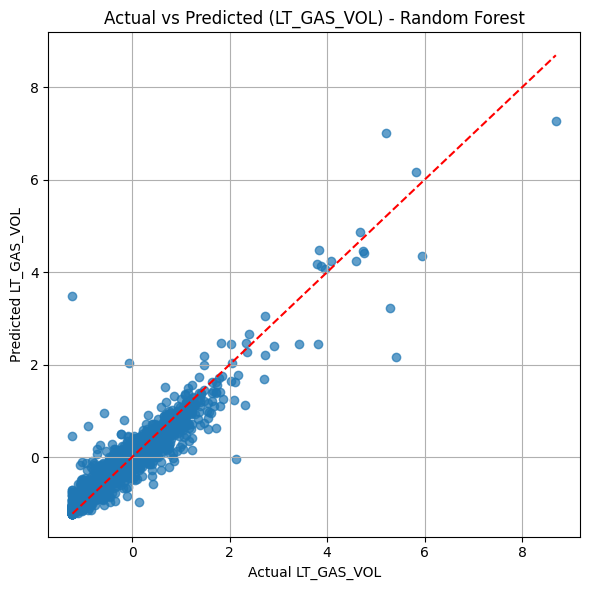

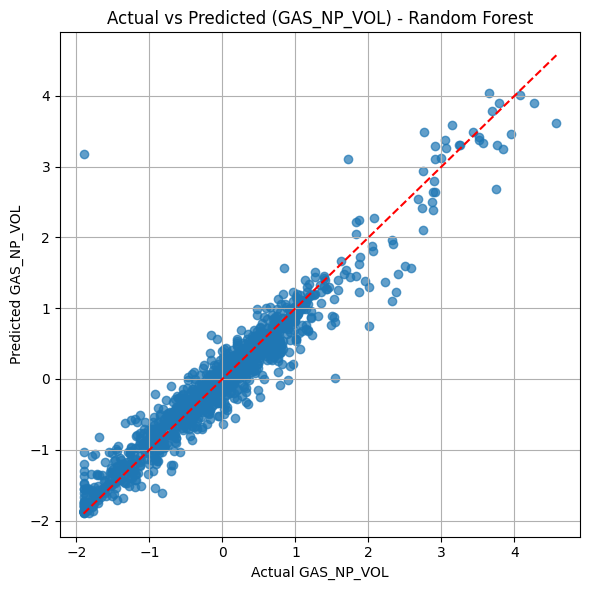

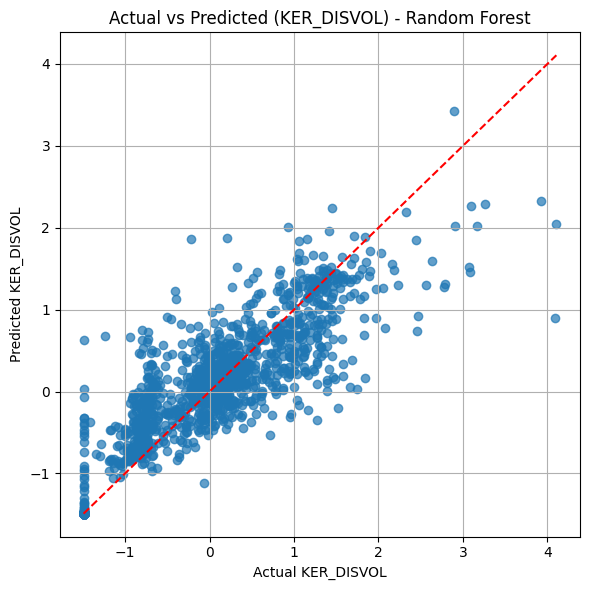

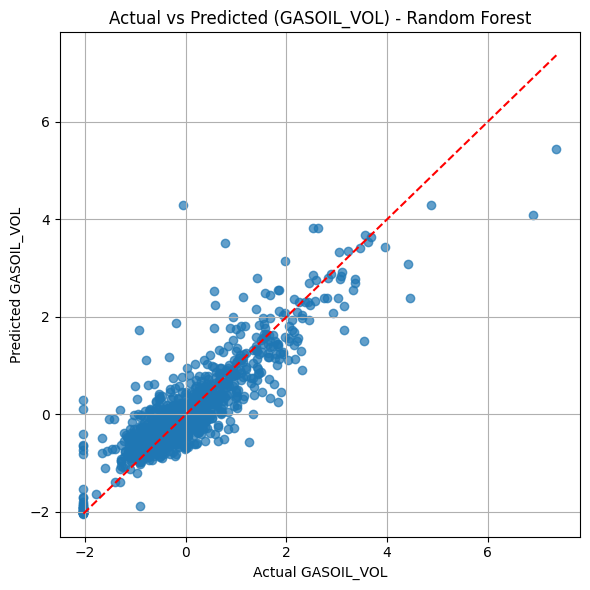

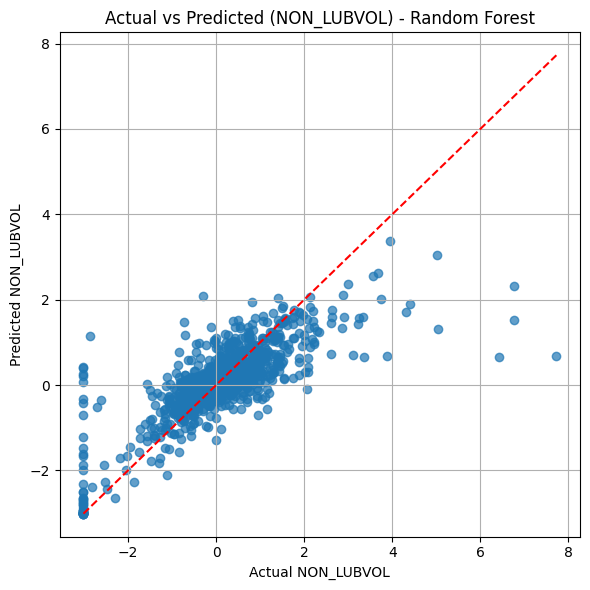

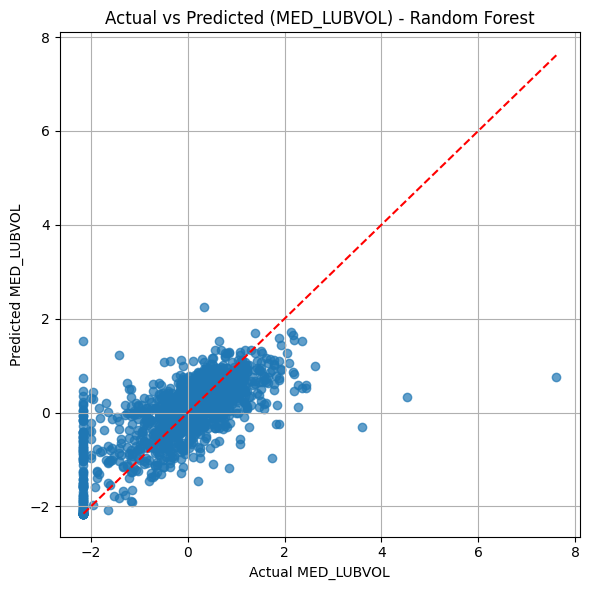

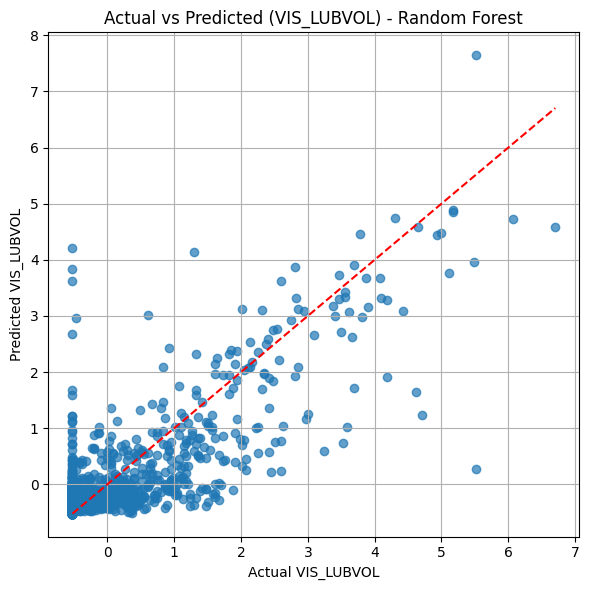

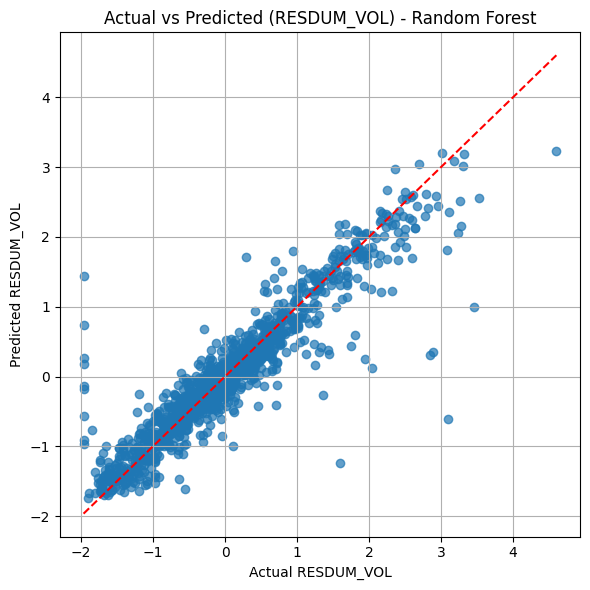

In [58]:
# Plot actual vs predicted values for Random Forest

for i, output in enumerate(output_features):

    plt.figure(figsize=(6, 6))

    plt.scatter(
        y_test_scaled[:, i],
        y_test_pred_forest[:, i],
        alpha=0.7
    )

    plt.plot(
        [y_test_scaled[:, i].min(), y_test_scaled[:, i].max()],
        [y_test_scaled[:, i].min(), y_test_scaled[:, i].max()],
        color="red",
        linestyle="--"
    )

    plt.xlabel("Actual " + output)
    plt.ylabel("Predicted " + output)
    plt.title("Actual vs Predicted (" + output + ") - Random Forest")

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [54]:
# MODEL COMPARISON

results_df = pd.DataFrame(results)

display(results_df)

,Model,Test RMSE,Test R²
0,"ANN (Hidden Layers 2, Neurons (32, 32), Learni...",3.763025,0.677578
1,Multiple Linear Regression (Scaled),0.679210,0.543299
2,"Random Forest (Trees 150, Depth 30, Min Split 2)",0.515473,0.740031


In [59]:
# Find the best model based on the lowest Test RMSE
best_model = results_df.loc[
    results_df["Test RMSE"].idxmin()
]

print("Best Model")

print(f"Model     : {best_model['Model']}")
print(f"Test RMSE : {best_model['Test RMSE']:.4f}")
print(f"Test R²   : {best_model['Test R²']:.4f}")

Best Model
Model     : Random Forest (Trees 150, Depth 30, Min Split 2)
Test RMSE : 0.5155
Test R²   : 0.7400


In [62]:
# ==========================================
# PREDICTING FOR NEW CRUDE OIL INPUTS
# ==========================================

# Input new data
new_data = {}
input_features_final = X.columns.tolist()

for feature in input_features_final:
    value = float(input(f"Enter {feature}: "))
    new_data[feature] = [value]

new_crude = pd.DataFrame(new_data)

# Scale the input data
new_crude_scaled = X_scaler.transform(new_crude)

# Predict using the best model
if "Linear Regression" in best_model["Model"]:

    prediction_scaled = linear_model.predict(new_crude_scaled)

elif "Random Forest" in best_model["Model"]:

    prediction_scaled = best_random_forest_model.predict(new_crude_scaled)

elif "Artificial Neural Network" in best_model["Model"]:

    prediction_scaled = best_ann_model.predict(
        new_crude_scaled,
        verbose=0
    )

# Convert predictions back to original units
prediction = y_scaler.inverse_transform(prediction_scaled)

# Display predictions
print("\nPredicted Crude Oil Product Fractions")
print("--------------------------------------")

for i, output in enumerate(output_features):
    print(f"{output}: {prediction[0][i]:.4f}")

Enter API_CRUDE: 42.5
Enter POUR_POINT: 5.0
Enter CRN: 0.035
Enter SU100: 37.0
Enter SRC: 0.24
Enter CAR_CR_WT: 0.6
Enter DLG: 0.680
Enter DGN: 0.734
Enter DKD: 0.810
Enter AVED: 0.840

Predicted Crude Oil Product Fractions
--------------------------------------
LT_GAS_VOL: 13.1712
GAS_NP_VOL: 38.9187
KER_DISVOL: 11.3631
GASOIL_VOL: 14.0328
NON_LUBVOL: 9.8981
MED_LUBVOL: 5.9804
VIS_LUBVOL: 0.1077
RESDUM_VOL: 18.4215
